In [3]:
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression, make_circles, make_blobs
from sklearn.preprocessing import StandardScaler

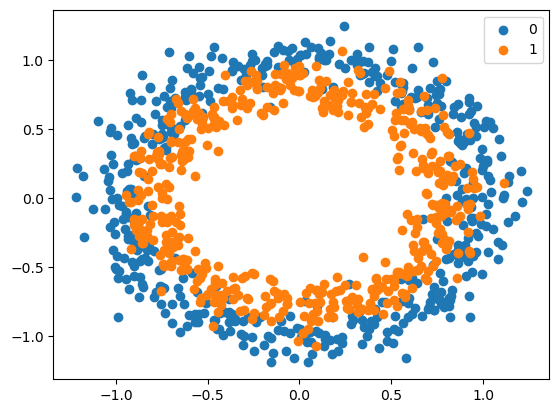

In [6]:
X, y = make_circles(n_samples=1000, noise=0.1, random_state=1)

plt.scatter(X[np.where((y==0)),0],X[np.where((y==0)),1], label='0')
plt.scatter(X[np.where((y==1)),0],X[np.where((y==1)),1], label='1')
plt.legend()
plt.show()

In [8]:
# Creación del modelo
## solo la ultima caap es con sigmoid
def build_model2(activation = 'sigmoid', loss='binary_crossentropy'):
  model = keras.models.Sequential()
  model.add(keras.layers.Dense(4, input_dim=2, activation='relu'))
  model.add(keras.layers.Dense(8, activation='relu'))
  model.add(keras.layers.Dense(1, activation = activation))
  opt = keras.optimizers.SGD(learning_rate=0.01)
  model.compile(loss=loss, optimizer=opt, metrics=['accuracy'])
  return model

C:\Users\Asus\miniconda3\envs\ml_env\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/1000
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.4700 - loss: 0.7084 - val_accuracy: 0.5220 - val_loss: 0.6978
Epoch 2/1000
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4660 - loss: 0.7075 - val_accuracy: 0.5220 - val_loss: 0.6974
Epoch 3/1000
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4620 - loss: 0.7068 - val_accuracy: 0.5260 - val_loss: 0.6971
Epoch 4/1000
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4600 - loss: 0.7061 - val_accuracy: 0.5240 - val_loss: 0.6969
Epoch 5/1000
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4600 - loss: 0.7055 - val_accuracy: 0.5240 - val_loss: 0.6967
Epoch 6/1000
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4580 - loss: 0.7049 - val_accuracy: 0.5220 - val_loss: 0.6965
Epoch 7/1000
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4520 - loss: 0.7045 - val_accuracy: 0.5160 - val_loss: 0.6963
Epoch 8/1000
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4540 - loss: 0.7039 - val_accu

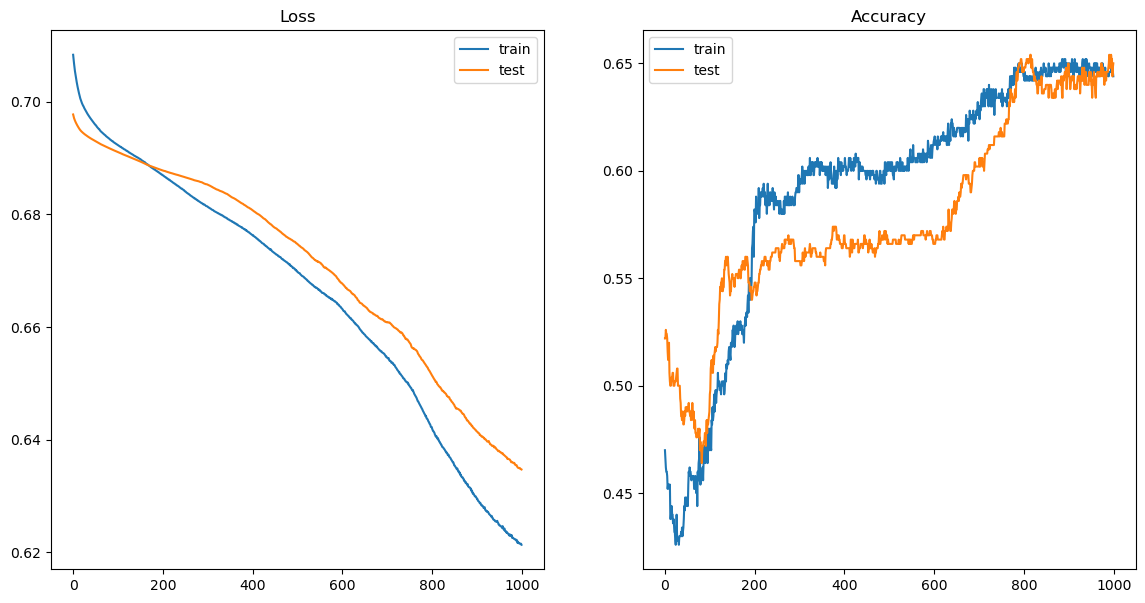

In [9]:
# binary cross entropy:
keras.backend.clear_session()
# Prerprocesado de los datos
n_train = 500
train_X, test_X = X[:n_train, :], X[n_train:, :]
train_y, test_y = y[:n_train], y[n_train:]
model = build_model2()
history = model.fit(train_X, train_y, validation_data=(test_X, test_y), epochs=1000, verbose=1)
# Evaluación del modelo
_, train_acc = model.evaluate(train_X, train_y, verbose=0)
_, test_acc = model.evaluate(test_X, test_y, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))
# Gráficas:
plt.figure(figsize=(14,7))
# Gráfica de pérdidas durante el entrenamiento
plt.subplot(121)
plt.title('Loss')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
# Gráfica de las precisión durante el entrenamiento
plt.subplot(122)
plt.title('Accuracy')
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.legend()
plt.show()

**LABORATORIO**


1. Para el dataset load digits, construir un modelo de red neuronal empleando keras para realizar la clasificación.

2. Para el dataset make a moon de sklearn, construir un modelo de una red neuronal con keras para clasificar los datos.n.

**Loan digits**

In [10]:
# Import the necessary modules
import numpy as np
#import tensorflow as tf
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

In [11]:
digits = load_digits(n_class=6)
X, y = digits.data, digits.target
n_samples, n_features = X.shape

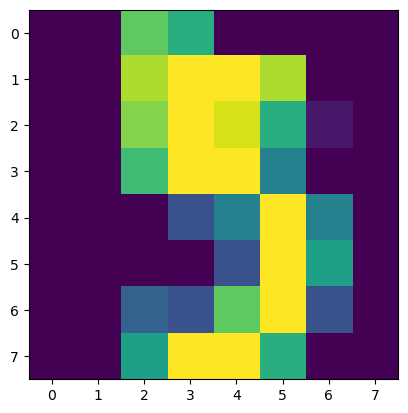

In [12]:
plt.imshow(X[5].reshape(8, 8))

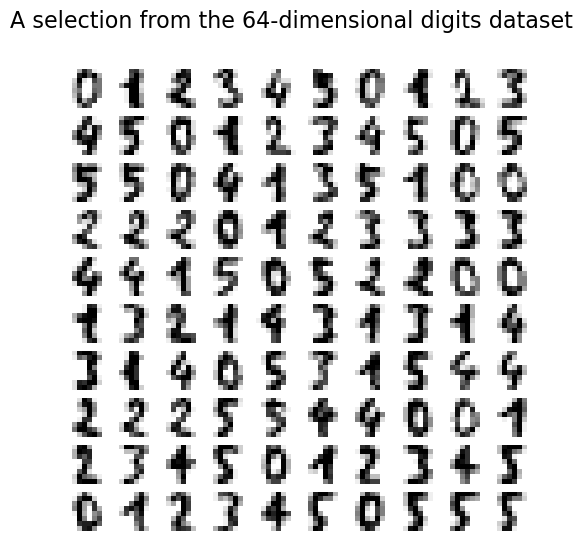

In [13]:
fig, axs = plt.subplots(nrows=10, ncols=10, figsize=(6, 6))
for idx, ax in enumerate(axs.ravel()):
    ax.imshow(X[idx].reshape((8, 8)), cmap=plt.cm.binary)
    ax.axis("off")
_ = fig.suptitle("A selection from the 64-dimensional digits dataset", fontsize=16)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
np.shape(X[0])

(64,)

In [7]:
X[0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

In [16]:
len(X)

1083

In [17]:
y

array([0, 1, 2, ..., 4, 4, 0])

y

In [18]:
## solo la ultima caap es con softmax, y con tantas salidas como clases
def build_model_loandigit(activation = 'softmax', loss='sparse_categorical_crossentropy'):
  model = keras.models.Sequential()
  model.add(keras.layers.Dense(40, input_dim=64, activation='relu'))
  model.add(keras.layers.Dense(18, activation='relu'))
  model.add(keras.layers.Dense(6, activation = activation))
  opt = keras.optimizers.SGD(learning_rate=0.01)
  model.compile(loss=loss, optimizer=opt, metrics=['accuracy'])
  return model

Epoch 1/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.4493 - loss: 1.8037 - val_accuracy: 0.6156 - val_loss: 1.0476
Epoch 2/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7480 - loss: 0.7002 - val_accuracy: 0.8348 - val_loss: 0.5326
Epoch 3/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9027 - loss: 0.3436 - val_accuracy: 0.8589 - val_loss: 0.4253
Epoch 4/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9373 - loss: 0.2184 - val_accuracy: 0.8979 - val_loss: 0.3431
Epoch 5/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9627 - loss: 0.1510 - val_accuracy: 0.8979 - val_loss: 0.3191
Epoch 6/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9680 - loss: 0.1234 - val_accuracy: 0.9039 - val_loss: 0.2826
Epoch 7/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9760 - loss: 0.0954 - val_accuracy: 0.9039 - val_loss: 0.2606
Epoch 8/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9813 - loss: 0.0771 - val_accuracy

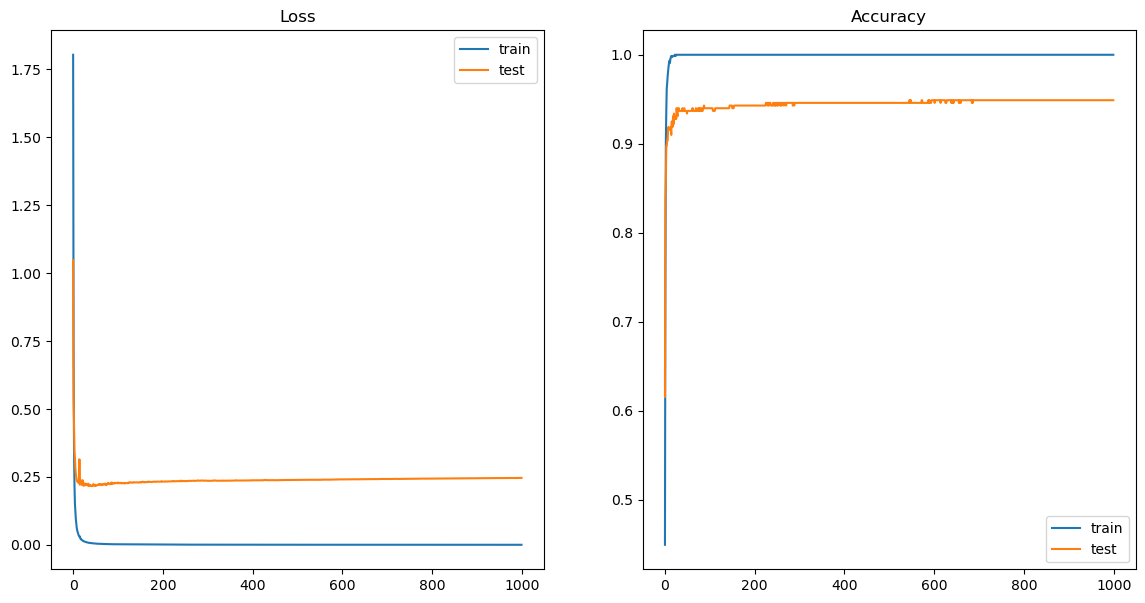

In [19]:
# binary cross entropy:
keras.backend.clear_session()
# Prerprocesado de los datos
n_train = 750
train_X, test_X = X[:n_train, :], X[n_train:, :]
train_y, test_y = y[:n_train], y[n_train:]
model = build_model_loandigit()
history = model.fit(train_X, train_y, validation_data=(test_X, test_y), epochs=1000, verbose=1)
# Evaluación del modelo
_, train_acc = model.evaluate(train_X, train_y, verbose=0)
_, test_acc = model.evaluate(test_X, test_y, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))
# Gráficas:
plt.figure(figsize=(14,7))
# Gráfica de pérdidas durante el entrenamiento
plt.subplot(121)
plt.title('Loss')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
# Gráfica de las precisión durante el entrenamiento
plt.subplot(122)
plt.title('Accuracy')
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.legend()
plt.show()

Epoch 1/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5680 - loss: 1.5768 - val_accuracy: 0.7357 - val_loss: 0.7638
Epoch 2/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9000 - loss: 0.3790 - val_accuracy: 0.8438 - val_loss: 0.4945
Epoch 3/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9507 - loss: 0.2022 - val_accuracy: 0.8408 - val_loss: 0.4564
Epoch 4/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9720 - loss: 0.1353 - val_accuracy: 0.8739 - val_loss: 0.3664
Epoch 5/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9800 - loss: 0.0973 - val_accuracy: 0.8859 - val_loss: 0.3257
Epoch 6/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9893 - loss: 0.0722 - val_accuracy: 0.8889 - val_loss: 0.3174
Epoch 7/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9880 - loss: 0.0574 - val_accuracy: 0.9069 - val_loss: 0.2940
Epoch 8/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9933 - loss: 0.0496 - val_accuracy: 0.

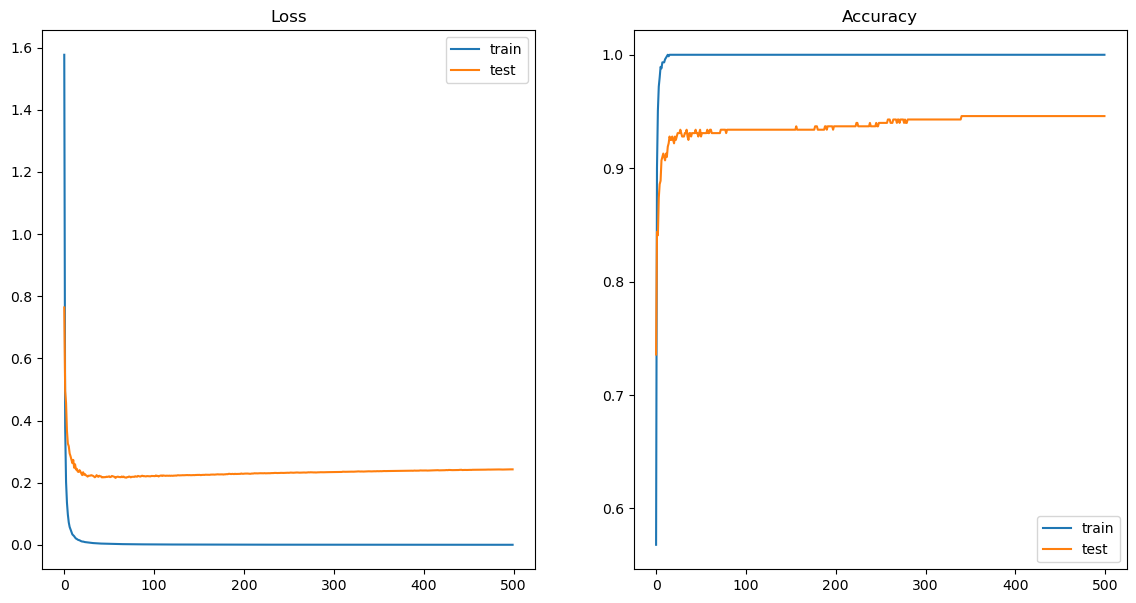

In [45]:
## solo la ultima caap es con softmax, y con tantas salidas como clases
def build_model2_loandigit(activation = 'softmax', loss='sparse_categorical_crossentropy'):
  model = keras.models.Sequential()
  model.add(keras.layers.Dense(60, input_dim=64, activation='relu'))
  model.add(keras.layers.Dense(40, activation='relu'))
  model.add(keras.layers.Dense(20, activation='relu'))
  model.add(keras.layers.Dense(6, activation = activation))
  opt = keras.optimizers.SGD(learning_rate=0.01)
  model.compile(loss=loss, optimizer=opt, metrics=['accuracy'])
  return model

X, y = digits.data, digits.target
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# binary cross entropy:
keras.backend.clear_session()
# Prerprocesado de los datos
n_train = 750
train_X, test_X = X[:n_train, :], X[n_train:, :]
train_y, test_y = y[:n_train], y[n_train:]
model = build_model2_loandigit()
history = model.fit(train_X, train_y, validation_data=(test_X, test_y), epochs=500, verbose=1)
# Evaluación del modelo
_, train_acc = model.evaluate(train_X, train_y, verbose=0)
_, test_acc = model.evaluate(test_X, test_y, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))
# Gráficas:
plt.figure(figsize=(14,7))
# Gráfica de pérdidas durante el entrenamiento
plt.subplot(121)
plt.title('Loss')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
# Gráfica de las precisión durante el entrenamiento
plt.subplot(122)
plt.title('Accuracy')
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.legend()
plt.show()

A pesar de haber agregado más neuronas y capas, el modelo no mejoró apreciablemente.

**Make moons**

In [31]:
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=500, noise=0.2, random_state=3)

In [32]:
X

array([[-3.36298938e-01,  1.06167458e+00],
       [ 1.02679681e-01,  1.61559272e-01],
       [ 6.45039054e-01,  5.49713259e-01],
       [-1.22710505e+00, -1.34821943e-01],
       [-8.01650123e-01,  6.55490102e-01],
       [ 1.34289248e+00, -2.42445767e-01],
       [ 7.19870424e-01, -1.55823686e-02],
       [ 7.26696917e-01,  5.39399760e-01],
       [-6.86881580e-01,  2.98205404e-01],
       [ 1.76858996e+00,  2.43190890e-01],
       [-6.11494099e-01,  9.67031261e-01],
       [-3.05062729e-01,  9.24479752e-01],
       [-6.51903213e-01,  1.49743350e-04],
       [ 5.35448853e-01, -3.14679655e-01],
       [ 1.55298872e+00,  4.94638424e-02],
       [-6.80223137e-01,  6.33954831e-01],
       [ 1.33461301e+00, -2.29662585e-01],
       [ 1.64765905e-01,  9.24853193e-01],
       [ 8.20311363e-01,  8.53295416e-01],
       [ 2.04807086e+00,  8.51478012e-02],
       [-5.05373634e-01,  1.24052976e+00],
       [ 1.93060482e-01,  9.74821591e-01],
       [ 2.26171425e+00,  2.32116971e-01],
       [ 1.

In [33]:
X[8]

array([-0.68688158,  0.2982054 ])

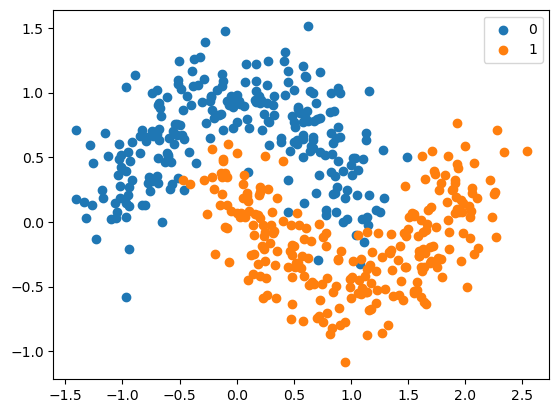

In [37]:
plt.scatter(X[np.where((y==0)),0],X[np.where((y==0)),1], label='0')
plt.scatter(X[np.where((y==1)),0],X[np.where((y==1)),1], label='1')
plt.legend()
plt.show()

In [40]:
X

array([[-3.36298938e-01,  1.06167458e+00],
       [ 1.02679681e-01,  1.61559272e-01],
       [ 6.45039054e-01,  5.49713259e-01],
       [-1.22710505e+00, -1.34821943e-01],
       [-8.01650123e-01,  6.55490102e-01],
       [ 1.34289248e+00, -2.42445767e-01],
       [ 7.19870424e-01, -1.55823686e-02],
       [ 7.26696917e-01,  5.39399760e-01],
       [-6.86881580e-01,  2.98205404e-01],
       [ 1.76858996e+00,  2.43190890e-01],
       [-6.11494099e-01,  9.67031261e-01],
       [-3.05062729e-01,  9.24479752e-01],
       [-6.51903213e-01,  1.49743350e-04],
       [ 5.35448853e-01, -3.14679655e-01],
       [ 1.55298872e+00,  4.94638424e-02],
       [-6.80223137e-01,  6.33954831e-01],
       [ 1.33461301e+00, -2.29662585e-01],
       [ 1.64765905e-01,  9.24853193e-01],
       [ 8.20311363e-01,  8.53295416e-01],
       [ 2.04807086e+00,  8.51478012e-02],
       [-5.05373634e-01,  1.24052976e+00],
       [ 1.93060482e-01,  9.74821591e-01],
       [ 2.26171425e+00,  2.32116971e-01],
       [ 1.

Epoch 1/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.4486 - loss: 0.8273 - val_accuracy: 0.4467 - val_loss: 0.8189
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4571 - loss: 0.8003 - val_accuracy: 0.4467 - val_loss: 0.7922
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4657 - loss: 0.7769 - val_accuracy: 0.4533 - val_loss: 0.7695
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4714 - loss: 0.7573 - val_accuracy: 0.4667 - val_loss: 0.7502
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4914 - loss: 0.7396 - val_accuracy: 0.5000 - val_loss: 0.7313
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5200 - loss: 0.7226 - val_accuracy: 0.5200 - val_loss: 0.7144
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5286 - loss: 0.7075 - val_accuracy: 0.5133 - val_loss: 0.6995
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5400 - loss: 0.6939 - val_accu

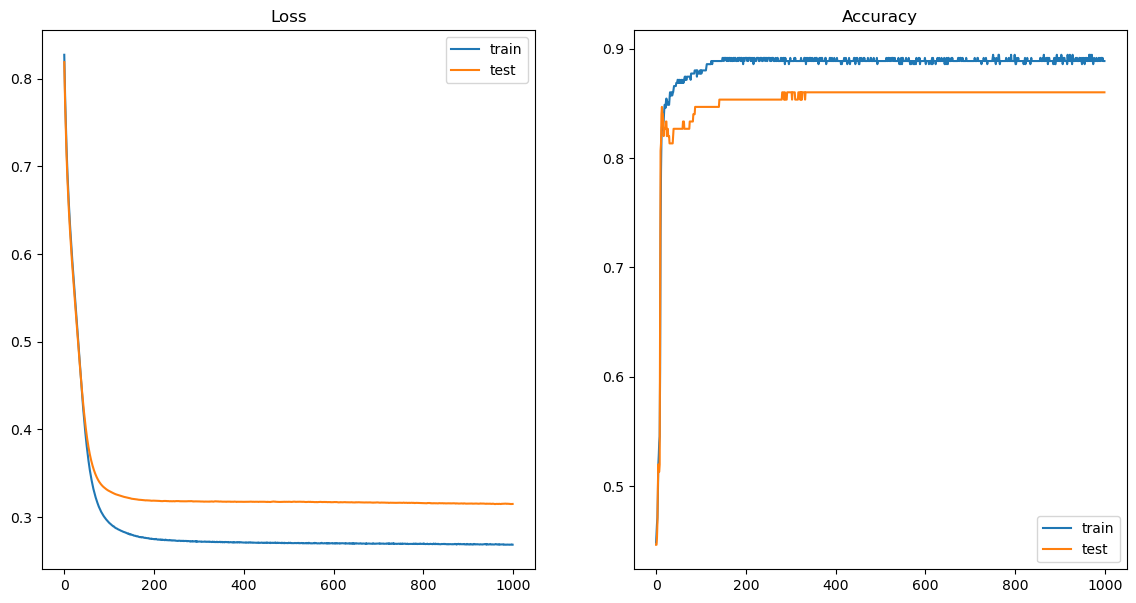

In [41]:
# binary cross entropy:
keras.backend.clear_session()
# Prerprocesado de los datos
n_train = 350
train_X, test_X = X[:n_train, :], X[n_train:, :]
train_y, test_y = y[:n_train], y[n_train:]
model_moon = build_model2()    ## uso el mismo modelo del ejemplo del principio     
history = model_moon.fit(train_X, train_y, validation_data=(test_X, test_y), epochs=1000, verbose=1)
# Evaluación del modelo
_, train_acc = model_moon.evaluate(train_X, train_y, verbose=0)
_, test_acc = model_moon.evaluate(test_X, test_y, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))
# Gráficas:
plt.figure(figsize=(14,7))
# Gráfica de pérdidas durante el entrenamiento
plt.subplot(121)
plt.title('Loss')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
# Gráfica de las precisión durante el entrenamiento
plt.subplot(122)
plt.title('Accuracy')
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.legend()
plt.show()